## Pulizia dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import copy 

In [2]:
with open('progress_anni.json', 'r') as f:
    progress_anni = json.load(f)

In [3]:
with open('new_merged_authors.json', 'r') as f:
    new_merged_authors = json.load(f)

##### Merge tra le info in new_merged_authors e gli autori in progress_anni

In [4]:
def year_merge(dict_1, dict_2):
    for author, data_2 in dict_2.items():
        # Se l'autore non esiste in dict_1 lo puoi ignorare
        # oppure creare ex-novo (qui lo ignoriamo)
        if author not in dict_1:
            continue

        years_1 = dict_1[author]['anno']
        years_2 = data_2['anno']

        for year, affiliations in years_2.items():
            if year not in years_1:
                years_1[year] = affiliations

    return dict_1

In [5]:
merged_authors = year_merge(new_merged_authors, progress_anni)

#### Pulizia

In [6]:
autori_singoli = []
for author, info in list(merged_authors.items()):
    if len(info['collaborators_by_paper']) <= 1: 
        autori_singoli.append(author)
        del merged_authors[author]

In [7]:
len(merged_authors)

46821

In [8]:
# Autori con un singolo paper
len(autori_singoli)

44324

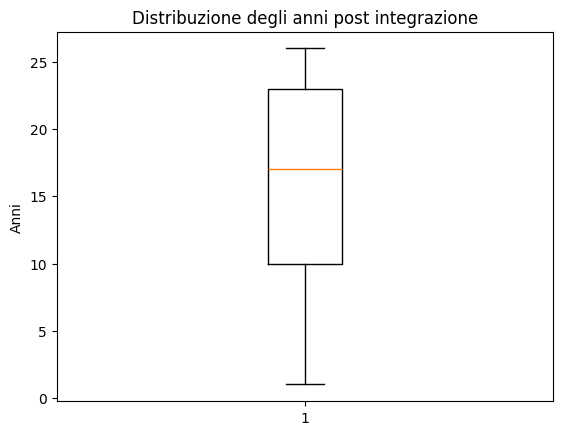

In [9]:
# Controllo della distribuzione degli anni
years_dist = {}

# Checking the number of years covered for each author
for author, infos in merged_authors.items():
    years_dist[author] = len(infos['anno'])

# Scatterplot to visualize the distribution
years = list(years_dist.values())

plt.boxplot(years)
plt.ylabel('Anni')
plt.title('Distribuzione degli anni post integrazione')
plt.show()

In [10]:
print('Media:', np.mean(years))
print('Mediana:', np.median(years))

Media: 15.79381046966105
Mediana: 17.0


In [11]:
# Controllo di quanti autori hanno più di quattro anni di fila assenti dalla propria entrata
def gap_check(dictionary):

    autori_con_gap_grande = {}

    for author, infos in dictionary.items():

        years = sorted(int(year) for year in infos['anno'].keys())

        for i in range(len(years) - 1):
            gap = years[i+1]-years[i]-1

            if gap > 4:
                autori_con_gap_grande[author] = [years[i+1], years[i], gap]
    
    return autori_con_gap_grande

In [12]:
autori_con_gap_grande = gap_check(merged_authors)

In [13]:
autori_con_gap_grande

{'Simone Magni': [2016, 2003, 12],
 'G. Santin': [2016, 2007, 8],
 'A. Liberati': [2015, 2009, 5],
 'Christian Enzinger': [2018, 2012, 5],
 'Maria‐Luisa Gorno‐Tempini': [2008, 2000, 7],
 'Bradley F. Boeve': [2020, 2011, 8],
 'G. Barbiellini': [2009, 2002, 6],
 'F. Bellardi': [2021, 2010, 10],
 'M. Ceccanti': [2021, 2012, 8],
 'D. Fabiani': [2021, 2012, 8],
 'M. Di Mauro': [2019, 2013, 5],
 'Antonino Casile': [2009, 2002, 6],
 'Gianpaolo Scalia Tomba': [2006, 2000, 5],
 'Annamaria Finardi': [2010, 2002, 7],
 'Karen Marder': [2020, 2007, 12],
 'M. Colombo': [2013, 2004, 8],
 'Christian Keysers': [2022, 2004, 17],
 'Ettore Bergamini': [2008, 2002, 5],
 'Samuel Bowles': [2024, 2014, 9],
 'Stefano Ferracuti': [2008, 2001, 6],
 'Christian Napoli': [2010, 2004, 5],
 'Alberto Chiesa': [2008, 2001, 6],
 'Nicola Filippini': [2021, 2015, 5],
 'Reto Huber': [2012, 2005, 6],
 'Alessandro Ciapetti': [2012, 2003, 8],
 'David Stuckler': [2017, 2011, 5],
 'Gianmarco De Francisci Morales': [2021, 2012, 

In [14]:
print(f'Il numero di autori con gap maggiori di quattro è {len(autori_con_gap_grande)}, che sono l\'{(len(autori_con_gap_grande)/len(merged_authors))*100:.2f}%')

Il numero di autori con gap maggiori di quattro è 5073, che sono l'10.83%


### Backward fill approach per due anni

Applichiamo un backward fill approach come Bilateral Flows, se ci sono buchi rimanenti li riempiamo con approccio fill-forward. Se ad un autore mancano anni fino da un certo punto alla fine, eliminiamo l'autore assumendo un cambiamento di carriera/la morte. 

In [15]:
#Ordiniamo le chiavi
years_dict = {}

for author, infos in merged_authors.items():
    years_dict[author] = sorted(infos['anno'].items())

Separare le funzioni: 
1. Controllo delle chiavi nel caso siano tutte presenti-> for author, anno in years_dict.items() e poi anni = anno.keys() if anni == lista di anni-> allora continue
1. Se le keys si fermano a meno di 2025-> riempire con fill forward per due anni, se ne mancano ancora eliminare l'autore assumendo cambio di carriera
2. Se mancano un numero minore o uguale a due in una sequenza-> creare una nuova chiave per i due anni precedenti a quello presente con la stessa affiliazione-> per esempio
se manca 2006-> years_dict[2006] = anno[affiliazione]
3. Se ne mancano in numero maggiore riempire con indici -1 e -2 dei mancanti con istituzione successiva e quelli rimanenti con la precedente

In [16]:
copy_years_dict = years_dict.copy()

In [17]:
# Normalizzazione del dizionario
for author, years in copy_years_dict.items():

    new_dict = {}

    for i in years:
        new_dict[i[0]] = i[1]
    
    copy_years_dict[author] = new_dict

In [18]:
copy_years_dict

{'Valter Torri': {'2000': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'}],
  '2001': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'},
   {'nome_istituzione': 'Azienda Socio Sanitaria Territoriale degli Spedali Civili di Brescia',
    'id': 'https://openalex.org/I4210103289'},
   {'nome_istituzione': 'Ospedale Infermi di Rimini',
    'id': 'https://openalex.org/I4210129405'},
   {'nome_istituzione': 'University of Brescia',
    'id': 'https://openalex.org/I79940851'}],
  '2002': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'},
   {'nome_istituzione': 'European Institute of Oncology',
    'id': 'https://openalex.org/I6141010'},
   {'nome_istituzione': 'University of Milano-Bicocca',
    'id': 'https://openalex.org/I66752286'},
   {'nome_istituzione': 'Ospedale Maggiore',
   

In [19]:
def backward_fill(dictionary, start=2000):
    # caricamento dei dati
    for author, years in dictionary.items():
        anni = list(sorted(int(y) for y in years.keys()))
        anni_aggiornati = years.copy()
        
        for year in years.keys():
            anno = int(year)
            
            if anno == start:  # se è uguale a 2000 non facciamo controllo backward
                continue
            
            for delta in (1, 2):
                anno_precedente = anno - delta
                
                if anno_precedente in anni:
                    continue
                
                anni_aggiornati[str(anno_precedente)] = years[year]

        dictionary[author] = anni_aggiornati
    
    return dictionary
        

In [20]:
new_copy = backward_fill(copy_years_dict, start = 2000)

In [21]:
new_copy #-> years è una lista di tuple

{'Valter Torri': {'2000': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'}],
  '2001': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'},
   {'nome_istituzione': 'Azienda Socio Sanitaria Territoriale degli Spedali Civili di Brescia',
    'id': 'https://openalex.org/I4210103289'},
   {'nome_istituzione': 'Ospedale Infermi di Rimini',
    'id': 'https://openalex.org/I4210129405'},
   {'nome_istituzione': 'University of Brescia',
    'id': 'https://openalex.org/I79940851'}],
  '2002': [{'nome_istituzione': 'Mario Negri Institute for Pharmacological Research',
    'id': 'https://openalex.org/I19630809'},
   {'nome_istituzione': 'European Institute of Oncology',
    'id': 'https://openalex.org/I6141010'},
   {'nome_istituzione': 'University of Milano-Bicocca',
    'id': 'https://openalex.org/I66752286'},
   {'nome_istituzione': 'Ospedale Maggiore',
   

Tenendo conto che useremo solamente t-2 e t-5, elimino tutti coloro che non hanno entrate post 2020. 

In [22]:
# Si eliminano gli autori che non hanno alcun paper registrato negli anni dal 2019 al 2024 e poi eliminiamo anche i riferimenti al 2025

def recent_authors(dizionario):

    autori_da_eliminare = []

    for author, years in dizionario.items():
        anni = list(sorted(int(y) for y in years.keys()))
        
        if not anni or anni[-1] < 2019:
            autori_da_eliminare.append(author)

    for autore in autori_da_eliminare:
        dizionario.pop(autore, None)

    # già che ci siamo rimuoviamo anche l'anno 2025
    # actually, no mi serve per calcolare gli studiosi usciti nel 2024
    #for author, years in dizionario.items():
        
    #    if '2025' in years.keys():
    #        del dizionario[author]['2025']

    return dizionario

In [23]:
recent_authors = recent_authors(new_copy)

Mettiamo in ordine cronologico gli anni.

In [24]:
for autore, anni in recent_authors.items():
    recent_authors[autore] = dict(sorted(anni.items(), key=lambda x: int(x[0])))

In [25]:
len(recent_authors)

41029

### Fill forward per anni rimanenti

In [26]:
def forward_fill(dizionario):

    for autore, anni in dizionario.items():

        # anni esistenti come interi
        years = sorted(int(y) for y in anni.keys())

        min_year = years[0]
        max_year = years[-1]

        for y in range(min_year, max_year + 1):

            y_str = str(y)

            if y_str not in anni:
                prev_year = str(y - 1)

                if prev_year not in anni:
                    raise ValueError(
                        f"Manca l'anno precedente ({prev_year}) per l'autore {autore}"
                    )

                # copia del valore dell'anno precedente
                anni[y_str] = copy.deepcopy(anni[prev_year])

        # controllo finale: nessun anno saltato
        final_years = sorted(int(y) for y in anni.keys())

        expected = list(range(min_year, max_year + 1))

        if final_years != expected:
            raise ValueError(
                f"Salti negli anni per l'autore {autore}"
            )

    return dizionario


In [27]:
complete_years = forward_fill(recent_authors)

In [28]:
len(complete_years)

41029

In [29]:
with open('storico_pulito.json', 'w') as infile:
    json.dump(complete_years, infile, indent=2)